# Projeto Água em Foco
## Análise histórica do Reservatório Jaguari-Jacareí

**Período analisado:** 01/01/2020 a 09/10/2026  
**Registros:** 2.474 medições diárias  
**Objetivo:** demonstrar um fluxo completo de tratamento, validação, análise temporal, visualização e exportação de dados.

> Este notebook utiliza a base já tratada e validada. O registro de 25/09/2026 foi preenchido anteriormente por interpolação linear entre os dias 24 e 26/09/2026.

## 1. Bibliotecas e configuração do projeto

A estrutura esperada é:

```text
Projeto cantareira/
├── dados/cantareira_base_validada.xlsx
├── graficos/
├── resultados/
└── notebooks/Analise_Cantareira_Final.ipynb
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# Localiza a raiz do projeto mesmo quando o notebook está na pasta notebooks
pasta_atual = Path.cwd()
pasta_projeto = pasta_atual.parent if pasta_atual.name.lower() in {"notebooks", "nootbooks"} else pasta_atual

pasta_dados = pasta_projeto / "dados"
pasta_graficos = pasta_projeto / "graficos"
pasta_resultados = pasta_projeto / "resultados"

pasta_graficos.mkdir(exist_ok=True)
pasta_resultados.mkdir(exist_ok=True)

arquivo_base = pasta_dados / "cantareira_base_validada.xlsx"
arquivo_tabelas = pasta_resultados / "tabelas_analiticas_cantareira_final.xlsx"

print("Projeto Água em Foco")
print("Raiz do projeto:", pasta_projeto)
print("Base localizada:", arquivo_base.exists())

Projeto Água em Foco
Raiz do projeto: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira
Base localizada: True


## 2. Carregamento e validação da base

In [2]:
if not arquivo_base.exists():
    raise FileNotFoundError(f"Base não encontrada: {arquivo_base}")

df = pd.read_excel(arquivo_base, engine="openpyxl")
df.columns = df.columns.astype(str).str.strip()

colunas_obrigatorias = [
    "Código", "Nome", "Cota (m)", "Volume Útil (hm³)",
    "Volume Útil (%)", "Afluência (m³/s)", "Defluência (m³/s)",
    "Data da Medição"
]

faltantes = [c for c in colunas_obrigatorias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas obrigatórias ausentes: {faltantes}")

df["Data da Medição"] = pd.to_datetime(df["Data da Medição"], errors="coerce")
colunas_numericas = [
    "Cota (m)", "Volume Útil (hm³)", "Volume Útil (%)",
    "Afluência (m³/s)", "Defluência (m³/s)"
]
for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df = df.sort_values("Data da Medição").reset_index(drop=True)

validacao = pd.DataFrame({
    "Indicador": [
        "Registros", "Data inicial", "Data final", "Datas duplicadas",
        "Valores numéricos ausentes", "Reservatórios"
    ],
    "Resultado": [
        len(df), df["Data da Medição"].min(), df["Data da Medição"].max(),
        int(df["Data da Medição"].duplicated().sum()),
        int(df[colunas_numericas].isna().sum().sum()),
        df["Nome"].nunique()
    ]
})

display(validacao)

if df["Data da Medição"].duplicated().any():
    raise ValueError("Existem datas duplicadas.")
if df[colunas_numericas].isna().any().any():
    raise ValueError("Existem valores numéricos ausentes.")

,Indicador,Resultado
0,Registros,2474
1,Data inicial,2020-01-01 00:00:00
2,Data final,2026-10-09 00:00:00
3,Datas duplicadas,0
4,Valores numéricos ausentes,0
5,Reservatórios,1


## 3. Preparação das variáveis analíticas

In [3]:
nomes_meses = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
}

df["Ano"] = df["Data da Medição"].dt.year
df["Mês"] = df["Data da Medição"].dt.month
df["Nome do Mês"] = df["Mês"].map(nomes_meses)
df["Ano-Mês"] = df["Data da Medição"].dt.to_period("M").astype(str)
df["Variação Diária Volume (p.p.)"] = df["Volume Útil (%)"].diff()
df["Balanço de Vazão (m³/s)"] = df["Afluência (m³/s)"] - df["Defluência (m³/s)"]
df["Volume MM7 (%)"] = df["Volume Útil (%)"].rolling(7, min_periods=1).mean()
df["Volume MM30 (%)"] = df["Volume Útil (%)"].rolling(30, min_periods=1).mean()
df["Afluência MM30 (m³/s)"] = df["Afluência (m³/s)"].rolling(30, min_periods=1).mean()
df["Defluência MM30 (m³/s)"] = df["Defluência (m³/s)"].rolling(30, min_periods=1).mean()

print("Variáveis analíticas criadas com sucesso.")
display(df.tail())

Variáveis analíticas criadas com sucesso.


,Código,Nome,Cota (m),Volume Útil (hm³),Volume Útil (%),Afluência (m³/s),Defluência (m³/s),Data da Medição,Ano,Mês,Nome do Mês,Ano-Mês,Variação Diária Volume (p.p.),Balanço de Vazão (m³/s),Volume MM7 (%),Volume MM30 (%),Afluência MM30 (m³/s),Defluência MM30 (m³/s)
2469,29001,JAGUARI-JACAREÍ,832.84,334.23,41.36,19.32,0.25,2026-10-05,2026,10,Outubro,2026-10,0.20,19.07,40.918571,38.229833,26.353000,0.25
2470,29001,JAGUARI-JACAREÍ,832.91,336.66,41.66,28.31,0.25,2026-10-06,2026,10,Outubro,2026-10,0.30,28.06,41.078571,38.508167,26.785333,0.25
2471,29001,JAGUARI-JACAREÍ,832.98,339.12,41.97,28.79,0.25,2026-10-07,2026,10,Outubro,2026-10,0.31,28.54,41.268571,38.788167,26.930000,0.25
2472,29001,JAGUARI-JACAREÍ,833.04,341.24,42.23,24.77,0.25,2026-10-08,2026,10,Outubro,2026-10,0.26,24.52,41.480000,39.075833,27.471667,0.25
2473,29001,JAGUARI-JACAREÍ,833.08,342.80,42.42,18.27,0.25,2026-10-09,2026,10,Outubro,2026-10,0.19,18.02,41.692857,39.367167,27.753000,0.25


## 4. Indicadores gerais

In [4]:
primeiro = df.iloc[0]
ultimo = df.iloc[-1]
idx_min = df["Volume Útil (%)"].idxmin()
idx_max = df["Volume Útil (%)"].idxmax()
idx_afl = df["Afluência (m³/s)"].idxmax()

indicadores_gerais = pd.DataFrame({
    "Indicador": [
        "Reservatório", "Data inicial", "Data final", "Registros",
        "Volume inicial (%)", "Volume atual (%)", "Variação no período (p.p.)",
        "Volume médio (%)", "Volume mínimo (%)", "Data do mínimo",
        "Volume máximo (%)", "Data do máximo", "Cota atual (m)",
        "Volume armazenado atual (hm³)", "Afluência atual (m³/s)",
        "Defluência atual (m³/s)", "Balanço atual (m³/s)",
        "Maior afluência (m³/s)", "Data da maior afluência"
    ],
    "Valor": [
        ultimo["Nome"], primeiro["Data da Medição"], ultimo["Data da Medição"], len(df),
        primeiro["Volume Útil (%)"], ultimo["Volume Útil (%)"],
        ultimo["Volume Útil (%)"] - primeiro["Volume Útil (%)"],
        df["Volume Útil (%)"].mean(), df.loc[idx_min, "Volume Útil (%)"],
        df.loc[idx_min, "Data da Medição"], df.loc[idx_max, "Volume Útil (%)"],
        df.loc[idx_max, "Data da Medição"], ultimo["Cota (m)"],
        ultimo["Volume Útil (hm³)"], ultimo["Afluência (m³/s)"],
        ultimo["Defluência (m³/s)"], ultimo["Balanço de Vazão (m³/s)"],
        df.loc[idx_afl, "Afluência (m³/s)"], df.loc[idx_afl, "Data da Medição"]
    ]
})
display(indicadores_gerais)

,Indicador,Valor
0,Reservatório,JAGUARI-JACAREÍ
1,Data inicial,2020-01-01 00:00:00
2,Data final,2026-10-09 00:00:00
3,Registros,2474
4,Volume inicial (%),40.97
5,Volume atual (%),42.42
6,Variação no período (p.p.),1.45
7,Volume médio (%),53.123232
8,Volume mínimo (%),16.79
9,Data do mínimo,2025-12-09 00:00:00


## 5. Resumos anual e mensal

In [5]:
resumo_anual = df.groupby("Ano", as_index=False).agg(
    Data_Inicial=("Data da Medição", "min"),
    Data_Final=("Data da Medição", "max"),
    Registros=("Data da Medição", "count"),
    Volume_Inicial_Pct=("Volume Útil (%)", "first"),
    Volume_Final_Pct=("Volume Útil (%)", "last"),
    Volume_Medio_Pct=("Volume Útil (%)", "mean"),
    Volume_Minimo_Pct=("Volume Útil (%)", "min"),
    Volume_Maximo_Pct=("Volume Útil (%)", "max"),
    Afluencia_Media_m3s=("Afluência (m³/s)", "mean"),
    Defluencia_Media_m3s=("Defluência (m³/s)", "mean"),
    Dias_Abaixo_40_Pct=("Volume Útil (%)", lambda s: int((s < 40).sum()))
)
resumo_anual["Variacao_Anual_pp"] = resumo_anual["Volume_Final_Pct"] - resumo_anual["Volume_Inicial_Pct"]
resumo_anual["Situacao_Ano"] = np.where(
    resumo_anual["Ano"].eq(df["Ano"].max()),
    "Parcial até " + df["Data da Medição"].max().strftime("%d/%m/%Y"),
    "Completo"
)

resumo_mensal = df.groupby(["Ano", "Mês", "Nome do Mês", "Ano-Mês"], as_index=False).agg(
    Data_Inicial=("Data da Medição", "min"),
    Data_Final=("Data da Medição", "max"),
    Registros=("Data da Medição", "count"),
    Volume_Inicial_Pct=("Volume Útil (%)", "first"),
    Volume_Final_Pct=("Volume Útil (%)", "last"),
    Volume_Medio_Pct=("Volume Útil (%)", "mean"),
    Volume_Minimo_Pct=("Volume Útil (%)", "min"),
    Volume_Maximo_Pct=("Volume Útil (%)", "max"),
    Afluencia_Media_m3s=("Afluência (m³/s)", "mean"),
    Defluencia_Media_m3s=("Defluência (m³/s)", "mean"),
    Balanco_Medio_m3s=("Balanço de Vazão (m³/s)", "mean")
)
resumo_mensal["Variacao_Mensal_pp"] = resumo_mensal["Volume_Final_Pct"] - resumo_mensal["Volume_Inicial_Pct"]

for tabela in (resumo_anual, resumo_mensal):
    cols = tabela.select_dtypes(include="number").columns
    tabela[cols] = tabela[cols].round(2)

display(resumo_anual)

,Ano,Data_Inicial,Data_Final,Registros,Volume_Inicial_Pct,Volume_Final_Pct,Volume_Medio_Pct,Volume_Minimo_Pct,Volume_Maximo_Pct,Afluencia_Media_m3s,Defluencia_Media_m3s,Dias_Abaixo_40_Pct,Variacao_Anual_pp,Situacao_Ano
0,2020,2020-01-01,2020-12-31,366,40.97,36.10,52.12,31.20,69.94,14.05,0.89,80,-4.87,Completo
1,2021,2021-01-01,2021-12-31,365,36.30,24.51,41.70,24.51,56.97,11.81,0.97,148,-11.79,Completo
2,2022,2022-01-01,2022-12-31,365,24.55,45.38,39.62,24.55,48.47,16.58,0.64,181,20.83,Completo
3,2023,2023-01-01,2023-12-31,365,46.01,81.91,82.83,46.01,94.11,26.00,0.43,0,35.90,Completo
4,2024,2024-01-01,2024-12-31,366,81.60,52.34,70.20,48.19,88.72,15.11,0.70,0,-29.26,Completo
5,2025,2025-01-01,2025-12-31,365,52.68,18.11,45.08,16.79,66.31,12.61,0.48,140,-34.57,Completo
6,2026,2026-01-01,2026-10-09,282,18.01,42.42,36.49,16.89,46.54,18.42,0.25,148,24.41,Parcial até 09/10/2026


## 6. Sazonalidade histórica

In [6]:
sazonalidade_mensal = resumo_mensal.groupby(["Mês", "Nome do Mês"], as_index=False).agg(
    Anos_Analisados=("Ano", "nunique"),
    Volume_Medio_Pct=("Volume_Medio_Pct", "mean"),
    Volume_Minimo_Pct=("Volume_Minimo_Pct", "min"),
    Volume_Maximo_Pct=("Volume_Maximo_Pct", "max"),
    Variacao_Mensal_Media_pp=("Variacao_Mensal_pp", "mean"),
    Afluencia_Media_m3s=("Afluencia_Media_m3s", "mean"),
    Defluencia_Media_m3s=("Defluencia_Media_m3s", "mean"),
    Balanco_Medio_m3s=("Balanco_Medio_m3s", "mean")
).sort_values("Mês")

sazonalidade_mensal["Comportamento_Medio"] = np.select(
    [sazonalidade_mensal["Variacao_Mensal_Media_pp"] > 0.10,
     sazonalidade_mensal["Variacao_Mensal_Media_pp"] < -0.10],
    ["Recuperação média", "Redução média"],
    default="Estabilidade média"
)

cols = sazonalidade_mensal.select_dtypes(include="number").columns
sazonalidade_mensal[cols] = sazonalidade_mensal[cols].round(2)
display(sazonalidade_mensal)

,Mês,Nome do Mês,Anos_Analisados,Volume_Medio_Pct,Volume_Minimo_Pct,Volume_Maximo_Pct,Variacao_Mensal_Media_pp,Afluencia_Media_m3s,Defluencia_Media_m3s,Balanco_Medio_m3s,Comportamento_Medio
0,1,Janeiro,7,45.75,16.89,82.42,6.11,26.19,0.33,25.85,Recuperação média
1,2,Fevereiro,7,54.76,20.97,85.52,9.90,37.68,0.33,37.35,Recuperação média
2,3,Março,7,63.07,33.11,92.38,5.96,26.08,0.32,25.76,Recuperação média
3,4,Abril,7,65.83,42.62,93.51,-0.51,15.58,0.43,15.15,Redução média
4,5,Maio,7,63.17,42.12,93.87,-3.44,10.97,0.64,10.32,Redução média
5,6,Junho,7,60.11,40.28,94.11,-2.88,10.34,0.50,9.84,Redução média
6,7,Julho,7,56.69,37.60,93.75,-4.20,7.38,0.78,6.60,Redução média
7,8,Agosto,7,51.47,33.11,91.19,-5.65,5.82,0.88,4.94,Redução média
8,9,Setembro,7,46.09,27.20,83.22,-4.25,8.75,1.29,7.46,Redução média
9,10,Outubro,7,42.99,22.90,82.82,-1.68,12.85,1.04,11.81,Redução média


## 7. Tendências recentes e eventos extremos

In [7]:
data_final = df["Data da Medição"].max()
volume_atual = df.iloc[-1]["Volume Útil (%)"]

def calcular_tendencia(dias):
    alvo = data_final - pd.Timedelta(days=dias)
    idx = (df["Data da Medição"] - alvo).abs().idxmin()
    referencia = df.loc[idx, "Volume Útil (%)"]
    variacao = volume_atual - referencia
    tendencia = "Alta" if variacao > 0.10 else "Queda" if variacao < -0.10 else "Estabilidade"
    return [f"{dias} dias", df.loc[idx, "Data da Medição"], referencia, data_final, volume_atual, variacao, tendencia]

tendencias_recentes = pd.DataFrame(
    [calcular_tendencia(d) for d in (1, 7, 30, 90)],
    columns=["Periodo", "Data_Referencia", "Volume_Referencia_Pct", "Data_Atual", "Volume_Atual_Pct", "Variacao_pp", "Tendencia"]
)

indices = {
    "Menor volume útil": df["Volume Útil (%)"].idxmin(),
    "Maior volume útil": df["Volume Útil (%)"].idxmax(),
    "Maior afluência diária": df["Afluência (m³/s)"].idxmax(),
    "Maior alta diária": df["Variação Diária Volume (p.p.)"].idxmax(),
    "Maior queda diária": df["Variação Diária Volume (p.p.)"].idxmin()
}

eventos_extremos = pd.DataFrame([
    ["Menor volume útil", df.loc[indices["Menor volume útil"], "Data da Medição"], df.loc[indices["Menor volume útil"], "Volume Útil (%)"], "%"],
    ["Maior volume útil", df.loc[indices["Maior volume útil"], "Data da Medição"], df.loc[indices["Maior volume útil"], "Volume Útil (%)"], "%"],
    ["Maior afluência diária", df.loc[indices["Maior afluência diária"], "Data da Medição"], df.loc[indices["Maior afluência diária"], "Afluência (m³/s)"], "m³/s"],
    ["Maior alta diária", df.loc[indices["Maior alta diária"], "Data da Medição"], df.loc[indices["Maior alta diária"], "Variação Diária Volume (p.p.)"], "p.p."],
    ["Maior queda diária", df.loc[indices["Maior queda diária"], "Data da Medição"], df.loc[indices["Maior queda diária"], "Variação Diária Volume (p.p.)"], "p.p."]
], columns=["Evento", "Data", "Valor", "Unidade"])

display(tendencias_recentes.round(2))
display(eventos_extremos.round(2))

C:\Users\tiago\AppData\Local\Temp\ipykernel_15948\818830948.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tendencias_recentes.round(2))


,Periodo,Data_Referencia,Volume_Referencia_Pct,Data_Atual,Volume_Atual_Pct,Variacao_pp,Tendencia
0,1 dias,2026-10-08,42.23,2026-10-09,42.42,0.19,Alta
1,7 dias,2026-10-02,40.93,2026-10-09,42.42,1.49,Alta
2,30 dias,2026-09-09,33.68,2026-10-09,42.42,8.74,Alta
3,90 dias,2026-07-11,41.10,2026-10-09,42.42,1.32,Alta


C:\Users\tiago\AppData\Local\Temp\ipykernel_15948\818830948.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(eventos_extremos.round(2))


,Evento,Data,Valor,Unidade
0,Menor volume útil,2025-12-09,16.79,%
1,Maior volume útil,2023-06-17,94.11,%
2,Maior afluência diária,2023-02-04,131.83,m³/s
3,Maior alta diária,2023-02-04,1.40,p.p.
4,Maior queda diária,2024-10-10,-0.39,p.p.


## 8. Gráfico 1: sazonalidade histórica do volume útil

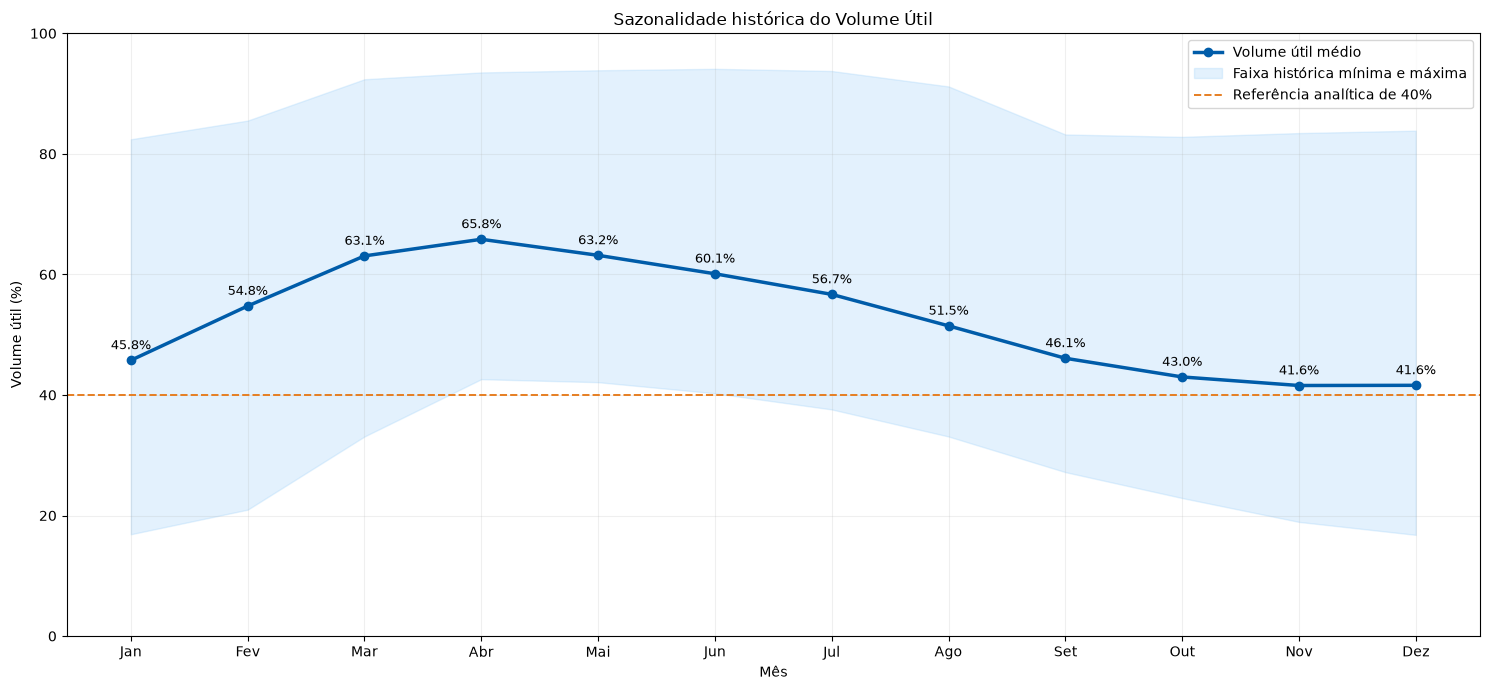

Salvo em: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira\graficos\07_sazonalidade_historica_volume.png


In [ ]:
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
arquivo = pasta_graficos / "07_sazonalidade_historica_volume.png"
fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(sazonalidade_mensal["Mês"], sazonalidade_mensal["Volume_Medio_Pct"], marker="o", linewidth=2.5, color="#005CA9", label="Volume útil médio")
ax.fill_between(sazonalidade_mensal["Mês"], sazonalidade_mensal["Volume_Minimo_Pct"], sazonalidade_mensal["Volume_Maximo_Pct"], color="#90CAF9", alpha=0.25, label="Faixa histórica mínima e máxima")
ax.axhline(40, color="#E67E22", linestyle="--", linewidth=1.4, label="Referência analítica de 40%")
ax.set(title="Sazonalidade histórica do Volume Útil", xlabel="Mês", ylabel="Volume útil (%)")
ax.set_xticks(range(1, 13), meses); ax.set_ylim(0, 100); ax.grid(alpha=0.20); ax.legend()
for _, linha in sazonalidade_mensal.iterrows():
    ax.annotate(f"{linha['Volume_Medio_Pct']:.1f}%", (linha["Mês"], linha["Volume_Medio_Pct"]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(arquivo, dpi=300, bbox_inches="tight", facecolor="white"); plt.show()
print("Salvo em:", arquivo)

## 9. Gráfico 2: comparação anual do volume útil

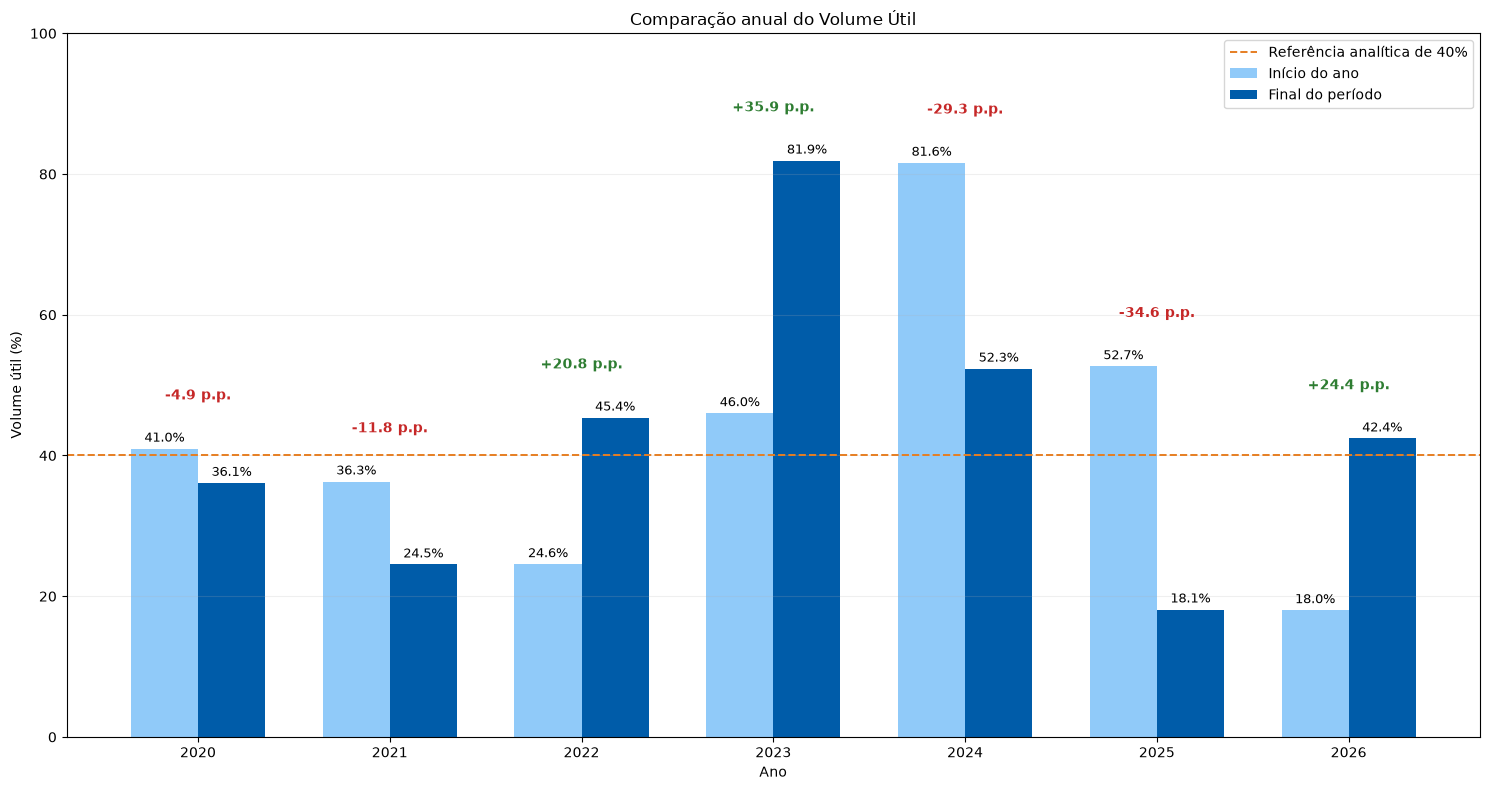

Salvo em: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira\graficos\08_comparacao_anual_volume_util.png


In [ ]:
arquivo = pasta_graficos / "08_comparacao_anual_volume_util.png"
dados = resumo_anual.copy(); pos = np.arange(len(dados)); largura = 0.35
fig, ax = plt.subplots(figsize=(15, 8))
b1 = ax.bar(pos-largura/2, dados["Volume_Inicial_Pct"], largura, color="#90CAF9", label="Início do ano")
b2 = ax.bar(pos+largura/2, dados["Volume_Final_Pct"], largura, color="#005CA9", label="Final do período")
ax.axhline(40, color="#E67E22", linestyle="--", linewidth=1.4, label="Referência analítica de 40%")
ax.set(title="Comparação anual do Volume Útil", xlabel="Ano", ylabel="Volume útil (%)")
ax.set_xticks(pos, dados["Ano"].astype(str)); ax.set_ylim(0, 100); ax.grid(axis="y", alpha=0.20); ax.legend()
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_x()+barra.get_width()/2, barra.get_height()+1, f"{barra.get_height():.1f}%", ha="center", fontsize=9)
for i, valor in enumerate(dados["Variacao_Anual_pp"]):
    cor = "#2E7D32" if valor >= 0 else "#C62828"
    ax.text(i, max(dados.loc[i, "Volume_Inicial_Pct"], dados.loc[i, "Volume_Final_Pct"])+7, f"{valor:+.1f} p.p.", ha="center", color=cor, fontweight="bold")
plt.tight_layout(); plt.savefig(arquivo, dpi=300, bbox_inches="tight", facecolor="white"); plt.show()
print("Salvo em:", arquivo)

## 10. Gráfico 3: balanço mensal entre afluência e defluência

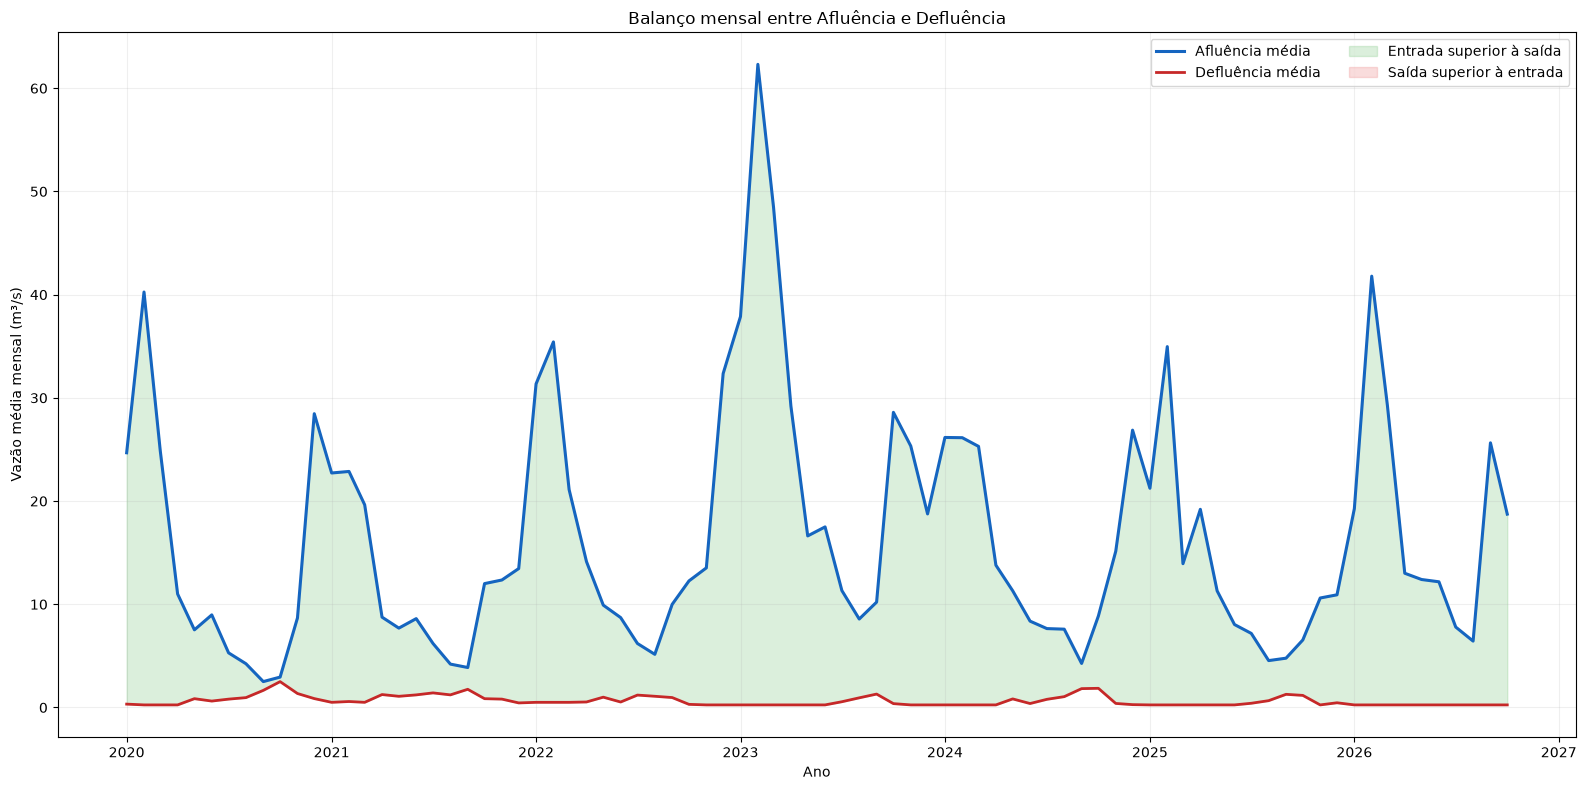

Salvo em: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira\graficos\09_balanco_mensal_vazoes.png


In [ ]:
balanco_mensal = df.groupby(["Ano", "Mês", "Nome do Mês", "Ano-Mês"], as_index=False).agg(
    Afluencia_Media_m3s=("Afluência (m³/s)", "mean"),
    Defluencia_Media_m3s=("Defluência (m³/s)", "mean"),
    Balanco_Medio_m3s=("Balanço de Vazão (m³/s)", "mean")
)
balanco_mensal["Data_Mensal"] = pd.to_datetime(balanco_mensal["Ano-Mês"] + "-01")
arquivo = pasta_graficos / "09_balanco_mensal_vazoes.png"
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(balanco_mensal["Data_Mensal"], balanco_mensal["Afluencia_Media_m3s"], color="#1565C0", linewidth=2.2, label="Afluência média")
ax.plot(balanco_mensal["Data_Mensal"], balanco_mensal["Defluencia_Media_m3s"], color="#C62828", linewidth=2.0, label="Defluência média")
ax.fill_between(balanco_mensal["Data_Mensal"], balanco_mensal["Afluencia_Media_m3s"], balanco_mensal["Defluencia_Media_m3s"], where=balanco_mensal["Afluencia_Media_m3s"] >= balanco_mensal["Defluencia_Media_m3s"], color="#81C784", alpha=0.28, interpolate=True, label="Entrada superior à saída")
ax.fill_between(balanco_mensal["Data_Mensal"], balanco_mensal["Afluencia_Media_m3s"], balanco_mensal["Defluencia_Media_m3s"], where=balanco_mensal["Afluencia_Media_m3s"] < balanco_mensal["Defluencia_Media_m3s"], color="#EF9A9A", alpha=0.34, interpolate=True, label="Saída superior à entrada")
ax.set(title="Balanço mensal entre Afluência e Defluência", xlabel="Ano", ylabel="Vazão média mensal (m³/s)")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y")); ax.grid(alpha=0.20); ax.legend(ncol=2)
plt.tight_layout(); plt.savefig(arquivo, dpi=300, bbox_inches="tight", facecolor="white"); plt.show()
print("Salvo em:", arquivo)

## 11. Conclusões do Projeto Água em Foco

O projeto analisou 2.474 medições diárias do reservatório Jaguari-Jacareí, abrangendo o período de 01/01/2020 a 09/10/2026. A análise foi construída a partir de uma base histórica que exigiu tratamento de formato, correção de valores numéricos, padronização de datas, validação da continuidade temporal e tratamento de um registro incompleto.

Após a preparação, a base consolidada apresentou:

ausência de datas duplicadas;
inexistência de lacunas no período analisado;
preenchimento do registro incompleto de 25/09/2026 por interpolação linear;
manutenção dos 2.474 registros diários;
disponibilidade de indicadores de volume útil, cota, afluência e defluência.
Comportamento histórico do volume útil

Ao longo da série, o volume útil apresentou oscilações expressivas, evidenciando períodos alternados de recuperação e redução do armazenamento.

O menor volume útil registrado foi de 16,79%, em 09/12/2025, enquanto o maior valor atingiu 94,11%, em 17/06/2023. A diferença entre esses extremos demonstra a amplitude do comportamento observado no período.

A série começou em 01/01/2020 com volume útil de 40,97% e terminou em 09/10/2026 com 42,42%, resultando em variação acumulada de +1,45 ponto percentual. Apesar da proximidade entre os valores inicial e final, o comportamento intermediário foi marcado por grandes ciclos de elevação e redução.

Comparação anual

A análise anual permitiu identificar diferentes ciclos:

2020: redução de aproximadamente 4,9 pontos percentuais;
2021: redução de aproximadamente 11,8 pontos percentuais;
2022: recuperação de aproximadamente 20,8 pontos percentuais;
2023: maior recuperação anual da série, com aproximadamente 35,9 pontos percentuais;
2024: redução de aproximadamente 29,3 pontos percentuais;
2025: maior retração anual observada, com aproximadamente 34,6 pontos percentuais;
2026: recuperação de aproximadamente 24,4 pontos percentuais até 09/10/2026.

O ano de 2026 deve ser interpretado como um período parcial. Ainda assim, os dados disponíveis indicam uma recuperação relevante em relação ao volume registrado no início do ano.

Situação em 2026

O volume útil estava próximo de 18% no começo de 2026 e chegou a 42,42% em 09/10/2026. Essa mudança representa recuperação superior a 24 pontos percentuais durante o período disponível.

Na comparação do dia 09 de outubro entre os sete anos analisados, 2026 ocupou a terceira posição, ficando abaixo dos maiores valores observados para essa mesma data, mas acima dos períodos historicamente mais críticos.

Esse resultado demonstra que a situação de outubro de 2026 era mais favorável do que a observada no início do próprio ano, embora ainda distante dos níveis mais elevados da série histórica.

Sazonalidade

A análise mensal mostrou um padrão sazonal no comportamento do volume útil.

De forma geral, os maiores valores médios ocorreram entre o final do primeiro trimestre e o segundo trimestre. A média histórica aumentou de aproximadamente 45,8% em janeiro para cerca de 65,8% em abril.

Após os meses de maior armazenamento, a série apresentou redução gradual:

aproximadamente 60,1% em junho;
aproximadamente 46,1% em setembro;
aproximadamente 43,0% em outubro;
aproximadamente 41,6% em novembro e dezembro.

Esse comportamento indica tendência histórica de recuperação nos primeiros meses do ano e redução ao longo dos meses seguintes. Entretanto, a grande diferença entre os valores mínimos e máximos de cada mês mostra que o comportamento não é uniforme entre os anos.

Afluência e defluência

A afluência apresentou variações significativas e picos sazonais, enquanto a defluência permaneceu em níveis inferiores durante grande parte da série.

A maior afluência diária registrada foi de 131,83 m³/s, em 04/02/2023. O gráfico mensal também mostrou um pico de afluência média no início de 2023, período associado à forte recuperação anual do volume útil.

Em outubro de 2026, considerando o período parcial disponível, foram observados aproximadamente:

18,74 m³/s de afluência média;
0,25 m³/s de defluência média;
+18,49 m³/s de balanço analítico médio.

A comparação direta entre afluência e defluência apresentou predominância de valores positivos. No entanto, esse resultado não deve ser interpretado como balanço hídrico integral, porque a base não contempla todos os componentes que influenciam o armazenamento.

Eventos relevantes

A análise detectou períodos de grande variação no volume útil, incluindo:

o mínimo histórico de 16,79% em 09/12/2025;
o máximo histórico de 94,11% em 17/06/2023;
a maior afluência diária de 131,83 m³/s em 04/02/2023;
a forte recuperação durante 2022 e 2023;
a redução acentuada durante 2024 e 2025;
a retomada do volume útil durante o período parcial de 2026.

Esses resultados mostram que a leitura isolada da última medição não é suficiente para compreender o comportamento do reservatório. A análise histórica, anual e sazonal fornece um contexto mais adequado para avaliar a situação observada.

Conclusão geral

O estudo demonstrou que o reservatório Jaguari-Jacareí apresentou ciclos relevantes de recuperação e redução entre 2020 e 2026. O período de maior armazenamento ocorreu em 2023, enquanto o ponto mais crítico da série foi registrado no final de 2025.

Em 2026, os dados indicaram recuperação significativa até 09/10/2026, levando o volume útil a 42,42%. Apesar dessa melhora, o nível ainda permaneceu consideravelmente abaixo do máximo histórico e das médias dos períodos mais favoráveis.

A principal conclusão é que o comportamento do reservatório deve ser analisado considerando simultaneamente:

a evolução histórica;
a sazonalidade;
a comparação com anos anteriores;
as tendências recentes;
o comportamento da afluência e da defluência;
as limitações da base disponível.

Essa abordagem permite uma interpretação mais consistente do que a observação isolada de uma única data ou indicador.

Competências demonstradas

O Projeto Água em Foco evidencia a aplicação prática das seguintes competências:

tratamento de arquivos com estrutura não convencional;
identificação do formato real de uma fonte de dados;
limpeza e padronização de dados;
validação de continuidade temporal;
tratamento documentado de valores ausentes;
construção de indicadores;
análise exploratória e temporal;
análise de sazonalidade;
comparação entre anos;
identificação de eventos extremos;
criação de visualizações analíticas;
automação da exportação de resultados;
comunicação de conclusões técnicas em linguagem executiva.
Limitações do estudo

Os resultados devem ser interpretados considerando as seguintes limitações:

A análise contempla somente o reservatório Jaguari-Jacareí.
A série de 2026 é parcial e termina em 09/10/2026.
O registro de 25/09/2026 foi preenchido por interpolação linear.
Não foram incorporados dados de precipitação, temperatura ou evaporação.
Não foram avaliadas regras operacionais de retirada, transferência ou gestão do sistema.
A diferença entre afluência e defluência não representa, isoladamente, o balanço hídrico integral.
A referência de 40% utilizada nos gráficos possui função exclusivamente analítica no portfólio.
As faixas de volume criadas no estudo não representam classificações oficiais, regulatórias ou operacionais.
Possibilidades de evolução

Como continuidade, o estudo poderá ser ampliado por meio de:

inclusão de outros reservatórios do Sistema Cantareira;
integração com dados históricos de precipitação;
análise da relação entre chuva, afluência e volume;
avaliação de defasagens temporais entre as variáveis;
desenvolvimento de projeções de curto prazo;
criação de atualização automática da base;
publicação dos resultados em uma aplicação interativa;
comparação entre períodos secos e chuvosos;
construção de indicadores integrados para o sistema completo.

## 12. Exportação das tabelas finais

In [ ]:
tabelas = {
    "Validacao": validacao,
    "Indicadores_Gerais": indicadores_gerais,
    "Resumo_Anual": resumo_anual,
    "Resumo_Mensal": resumo_mensal,
    "Sazonalidade": sazonalidade_mensal,
    "Tendencias_Recentes": tendencias_recentes,
    "Eventos_Extremos": eventos_extremos,
    "Balanco_Mensal": balanco_mensal,
    "Base_Analitica": df
}

with pd.ExcelWriter(arquivo_tabelas, engine="openpyxl", datetime_format="dd/mm/yyyy", date_format="dd/mm/yyyy") as writer:
    for nome, tabela in tabelas.items():
        tabela.to_excel(writer, sheet_name=nome, index=False)

print("Notebook executado com sucesso.")
print("Excel final:", arquivo_tabelas)
print("Gráficos:", pasta_graficos)

Notebook executado com sucesso.
Excel final: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira\resultados\tabelas_analiticas_cantareira_final.xlsx
Gráficos: c:\Users\tiago\OneDrive\Desktop\Projeto cantareira\graficos
